# Evaluación por máquina y por modelo

Matrices de confusión, predicciones, duración de colas (bloques seguidos) y tendencias de cuándo y por qué ocurren.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score,
)

from setup import common_test_rows, load_test_data, prepare_models
from setup_arima_sarima import evaluate_arima_sarima

BLOCK_HOURS = 0.5            # cada bloque = 30 min
MAX_ROWS_PRINT = 20          # filas que se imprimen por máquina-modelo (CSV completo se guarda)
DRIVER_COLUMNS = [           # variables para explicar "por qué" arranca una cola
    "total_ordenios", "pct_ocupacion_robot", "duracion_total_min",
    "patadas_totales", "desviaciones_leche_totales", "ordenios_con_lavado",
    "hubo_lavado", "ordenios_otros_robots", "vacas_activas_dia",
]

data = load_test_data()
models, predictions = prepare_models(data)
arima_predictions, arima_metrics = evaluate_arima_sarima(data)
for name in ("ARIMA", "SARIMA"):
    model_rows = arima_predictions.loc[arima_predictions["Modelo"] == name]
    predictions[name] = model_rows.set_index("__row_id__")["Prediccion"]

# Umbral de decisión por modelo (GRU y logística traen el suyo; ARIMA/SARIMA, uno por máquina).
THRESHOLDS = {name: 0.5 for name in predictions}
THRESHOLDS["GRU"] = data.gru_decision_threshold
THRESHOLDS["Regresión logística"] = data.logistic_decision_threshold
for name in ("ARIMA", "SARIMA"):
    model_rows = arima_predictions.loc[arima_predictions["Modelo"] == name]
    THRESHOLDS[name] = model_rows.set_index("__row_id__")["Umbral"]

common_rows = common_test_rows(data, predictions)
print(f"Filas de test compartidas: {len(common_rows):,} de {len(data.test):,}")
print("Umbrales:", {
    name: "por máquina" if isinstance(value, pd.Series) else value
    for name, value in THRESHOLDS.items()
})
print("Métricas globales ARIMA/SARIMA:")
print(arima_metrics.round(3).to_string())

Datos: 179,850 filas; train=125,894, validación=26,978, test=26,978
Test cronológico: 2025-06-27 15:30:00 -> 2025-12-31 23:30:00
Modelos disponibles: ['gru_E2_w48.keras', 'gru_E2_w48_scaler.joblib', 'logistic_regresion.keras', 'lstm_base.keras', 'lstm_dense.keras', 'lstm_model.keras', 'lstm_norm.keras', 'lstm_norm_drop.keras', 'mlp_classifier.joblib', 'tcn_classification_base_w48.keras']


c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to

Variables de entrada: {'Regresión logística': 25, 'LSTM': (24, 29), 'GRU/TCN': (48, 27), 'MLPClassifier': 41}
Filas de test con predicción por modelo: {'GRU': 26978, 'TCN': 26978, 'LSTM': 26978, 'Regresión logística': 26978, 'MLPClassifier': 26978}
Filas de test compartidas: 26,978 de 26,978
Umbrales: {'GRU': 0.35, 'TCN': 0.5, 'LSTM': 0.5, 'Regresión logística': 0.20948471128940582, 'MLPClassifier': 0.5, 'ARIMA': 'por máquina', 'SARIMA': 'por máquina'}
Métricas globales ARIMA/SARIMA:
                       N  Precision  Recall     F1    MAE   RMSE     R2
Modelo                                                                 
ARIMA              26978      0.575   1.000  0.730  0.318  0.373  0.073
SARIMA             26978      0.604   0.959  0.741  0.373  0.428 -0.221
Persistencia       26978      0.667   0.667  0.667  0.338  0.462 -0.420
Mismo bloque ayer  26978      0.650   0.649  0.650  0.340  0.472 -0.484
Siempre cola       26978      0.575   1.000  0.730    NaN    NaN    NaN


## Base común (real)

In [13]:
if "hubo_ordenios" not in data.full_data.columns:
    raise ValueError("Falta la columna 'hubo_ordenios' para separar producción e inactividad.")

driver_cols = [c for c in DRIVER_COLUMNS if c in data.full_data.columns]
base_cols = ["bloque_tiempo", "ms", "hora", "dia_semana", "temporada", data.target,
             "hubo_ordenios"] + driver_cols
base = data.full_data.set_index("__row_id__").loc[common_rows, base_cols].copy()
base["bloque_tiempo"] = pd.to_datetime(base["bloque_tiempo"])
base["y_true"] = (base[data.target] > data.label_threshold).astype(int)
base = base.sort_values(["ms", "bloque_tiempo"])
machines = sorted(base["ms"].dropna().unique())
model_names = list(predictions)

frames = {}  # (modelo) -> DataFrame con score y y_pred
for name in model_names:
    df = base.copy()
    df["score"] = predictions[name].reindex(df.index).to_numpy(dtype=float)
    threshold = THRESHOLDS[name]
    if isinstance(threshold, pd.Series):
        threshold = threshold.reindex(df.index)
        if threshold.isna().any():
            raise ValueError(f"Faltan umbrales de decisión para {name} en filas compartidas.")
        threshold = threshold.to_numpy(dtype=float)
    df["y_pred"] = (df["score"] >= threshold).astype(int)
    frames[name] = df

## Cola y producción: segmentos productivos e inactividad

La cola real usa el umbral existente del 50%. La primera gráfica compara cola vs. no cola solo entre bloques con producción; la segunda muestra la composición de todos los bloques compartidos de test, incluyendo tiempo sin producción. La producción se identifica con `hubo_ordenios`.

   ms  bloques_test  cola_en_bloques_productivos_%  produccion_sin_cola_%  tiempo_inactivo_%  cola_sin_produccion_%
VMS 1          8992                          71.54                  28.46              11.84                    0.0
VMS 2          8993                          63.86                  36.14              11.14                    0.0
VMS 3          8993                          59.34                  40.66              11.05                    0.0


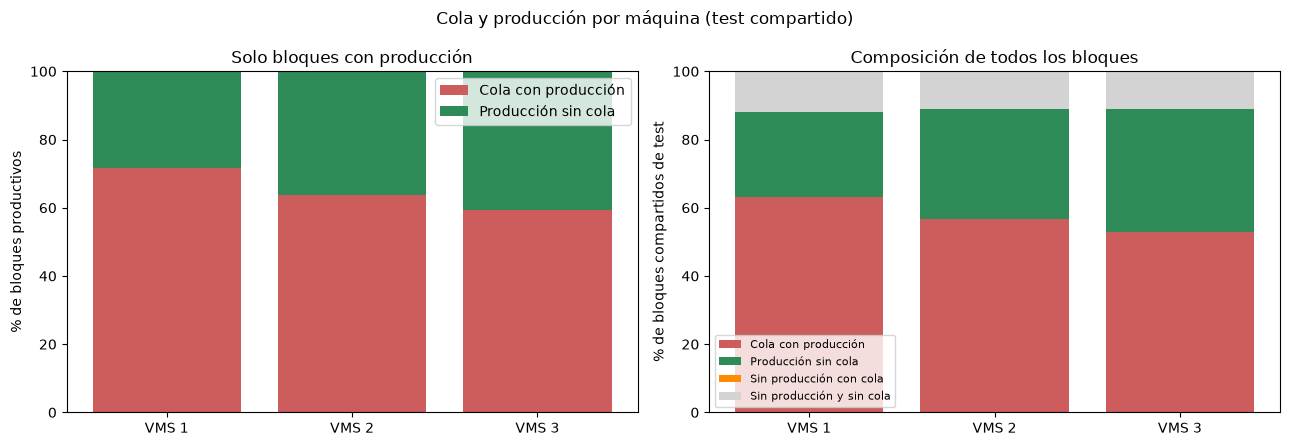

In [14]:
activity_rows = []
for machine, group in base.groupby("ms", sort=True):
    production = group["hubo_ordenios"].eq(1)
    queue = group["y_true"].eq(1)
    productive_blocks = int(production.sum())
    queue_with_production = int((production & queue).sum())
    no_queue_with_production = int((production & ~queue).sum())
    no_production_with_queue = int((~production & queue).sum())
    no_production_without_queue = int((~production & ~queue).sum())

    activity_rows.append({
        "ms": machine,
        "bloques_test": len(group),
        "cola_en_bloques_productivos_%": (
            100 * queue_with_production / productive_blocks if productive_blocks else np.nan
        ),
        "produccion_sin_cola_%": (
            100 * no_queue_with_production / productive_blocks if productive_blocks else np.nan
        ),
        "tiempo_inactivo_%": 100 * (len(group) - productive_blocks) / len(group),
        "cola_sin_produccion_%": 100 * no_production_with_queue / len(group),
    })

activity_summary = pd.DataFrame(activity_rows)
print(activity_summary.round(2).to_string(index=False))

x = np.arange(len(activity_summary))
queue_productive = activity_summary["cola_en_bloques_productivos_%"].to_numpy()
no_queue_productive = activity_summary["produccion_sin_cola_%"].to_numpy()
queue_idle = activity_summary["cola_sin_produccion_%"].to_numpy()
all_queue = []
all_no_queue = []
all_idle_queue = []
all_idle_no_queue = []
for machine, group in base.groupby("ms", sort=True):
    production = group["hubo_ordenios"].eq(1)
    queue = group["y_true"].eq(1)
    n = len(group)
    all_queue.append(100 * (production & queue).sum() / n)
    all_no_queue.append(100 * (production & ~queue).sum() / n)
    all_idle_queue.append(100 * (~production & queue).sum() / n)
    all_idle_no_queue.append(100 * (~production & ~queue).sum() / n)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(x, queue_productive, label="Cola con producción", color="indianred")
axes[0].bar(x, no_queue_productive, bottom=queue_productive,
            label="Producción sin cola", color="seagreen")
axes[0].set_title("Solo bloques con producción")
axes[0].set_ylabel("% de bloques productivos")
axes[0].set_ylim(0, 100)
axes[0].set_xticks(x, activity_summary["ms"])
axes[0].legend()

bottom = np.zeros(len(x))
for values, label, color in [
    (all_queue, "Cola con producción", "indianred"),
    (all_no_queue, "Producción sin cola", "seagreen"),
    (all_idle_queue, "Sin producción con cola", "darkorange"),
    (all_idle_no_queue, "Sin producción y sin cola", "lightgray"),
]:
    axes[1].bar(x, values, bottom=bottom, label=label, color=color)
    bottom += np.asarray(values)
axes[1].set_title("Composición de todos los bloques")
axes[1].set_ylabel("% de bloques compartidos de test")
axes[1].set_ylim(0, 100)
axes[1].set_xticks(x, activity_summary["ms"])
axes[1].legend(fontsize=8)
fig.suptitle("Cola y producción por máquina (test compartido)")
fig.tight_layout()
plt.show()

## 1) Métricas + matrices de confusión por máquina-modelo

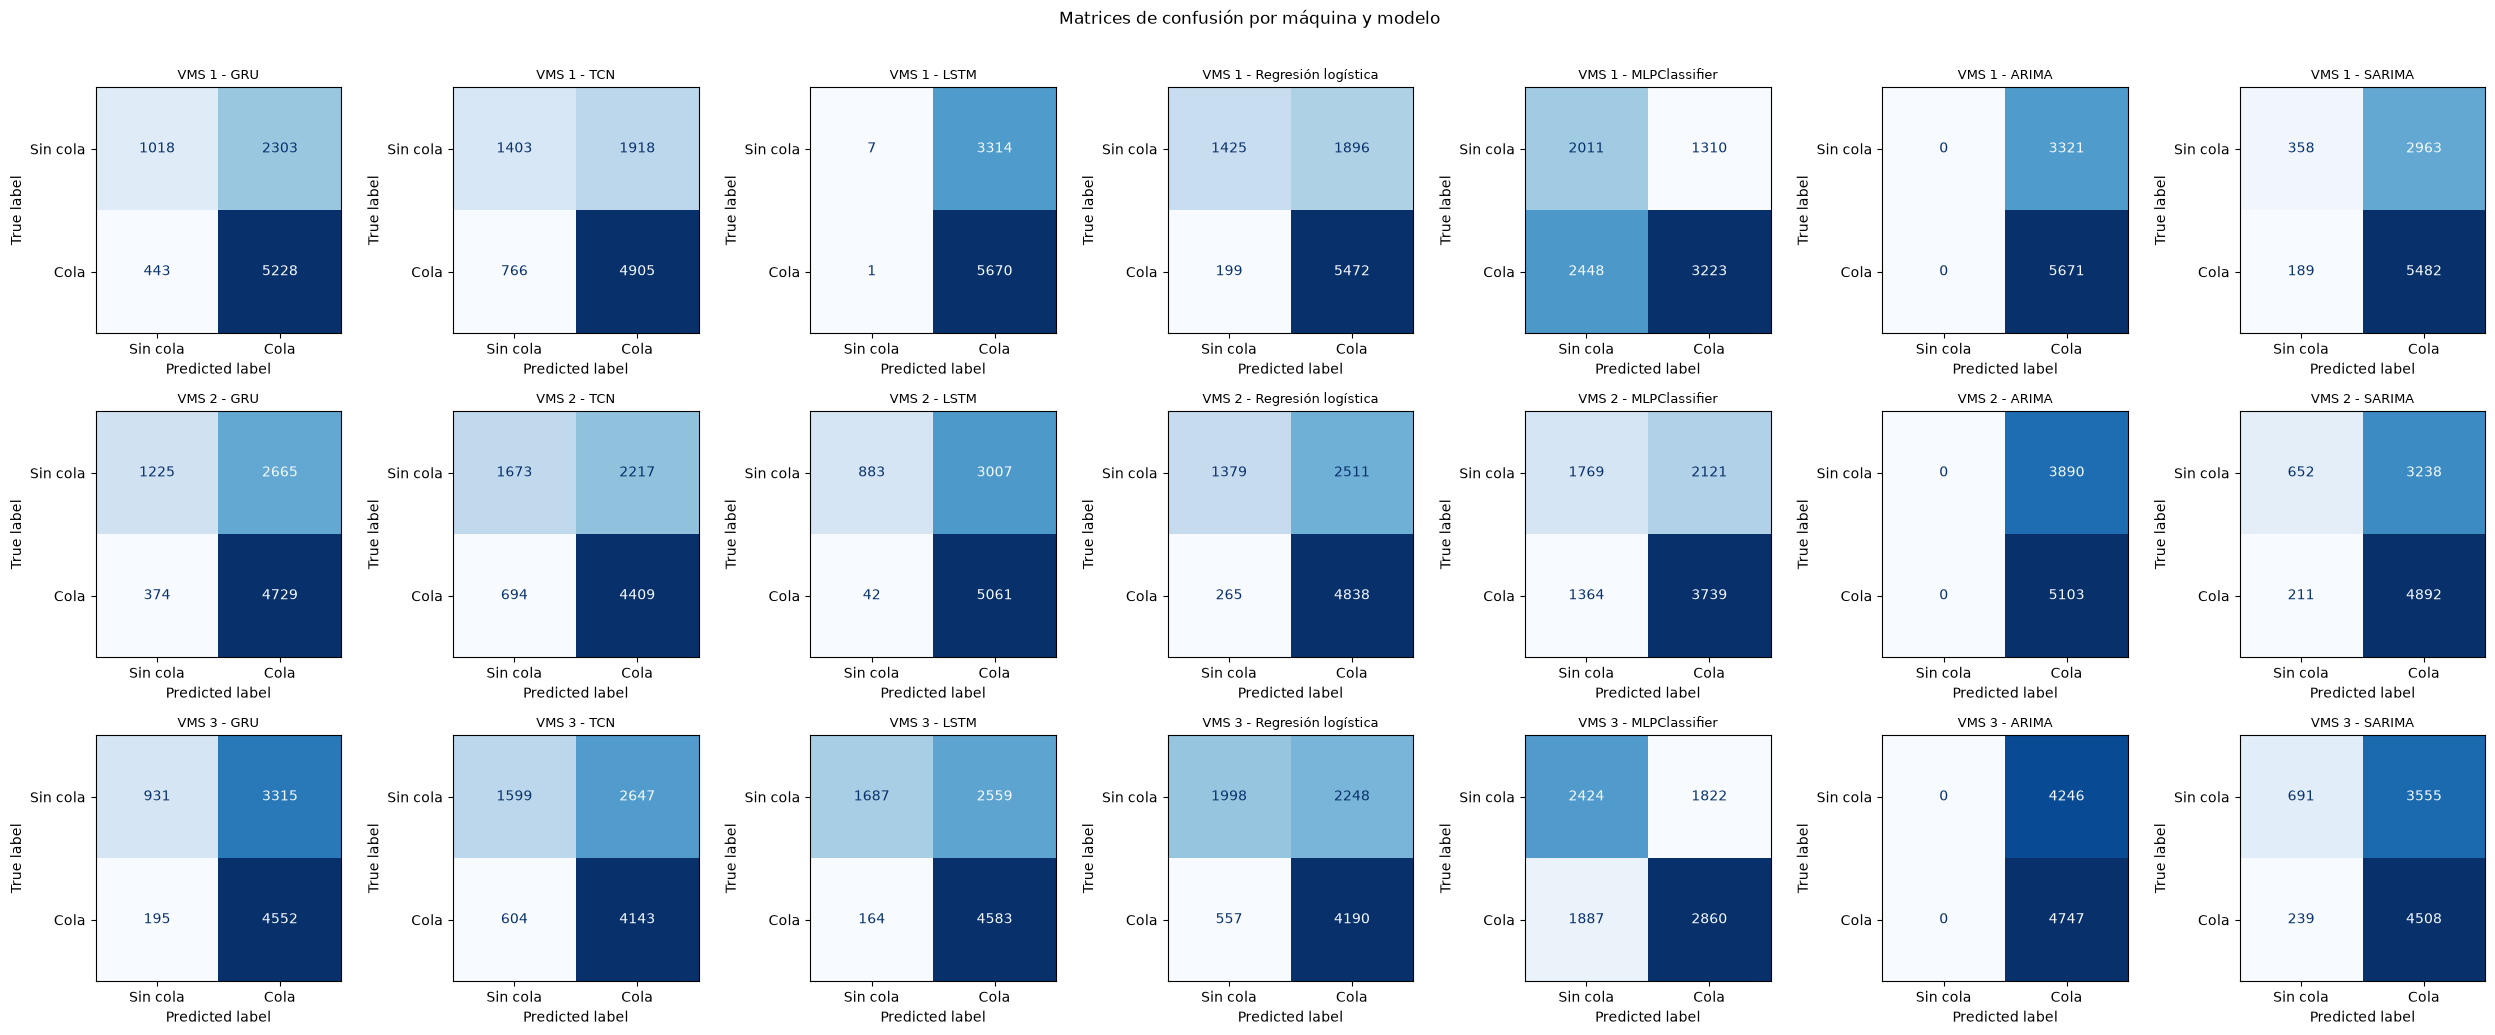

   ms              modelo    n  cola_real_%  cola_pred_%   TN   FP   FN   TP  accuracy  precision  recall    f1
VMS 1                 GRU 8992       63.067       83.752 1018 2303  443 5228     0.695      0.694   0.922 0.792
VMS 1                 TCN 8992       63.067       75.879 1403 1918  766 4905     0.702      0.719   0.865 0.785
VMS 1                LSTM 8992       63.067       99.911    7 3314    1 5670     0.631      0.631   1.000 0.774
VMS 1 Regresión logística 8992       63.067       81.940 1425 1896  199 5472     0.767      0.743   0.965 0.839
VMS 1       MLPClassifier 8992       63.067       50.411 2011 1310 2448 3223     0.582      0.711   0.568 0.632
VMS 1               ARIMA 8992       63.067      100.000    0 3321    0 5671     0.631      0.631   1.000 0.774
VMS 1              SARIMA 8992       63.067       93.917  358 2963  189 5482     0.649      0.649   0.967 0.777
VMS 2                 GRU 8993       56.744       82.220 1225 2665  374 4729     0.662      0.640   0.92

In [15]:
metric_rows = []
fig, axes = plt.subplots(
    len(machines), len(model_names),
    figsize=(3.6 * len(model_names), 3.4 * len(machines)), squeeze=False,
)
for i, machine in enumerate(machines):
    for j, name in enumerate(model_names):
        g = frames[name].loc[frames[name]["ms"] == machine]
        cm = confusion_matrix(g["y_true"], g["y_pred"], labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["Sin cola", "Cola"]).plot(
            ax=axes[i, j], colorbar=False, values_format="d", cmap="Blues"
        )
        axes[i, j].set_title(f"{machine} - {name}", fontsize=9)
        tn, fp, fn, tp = cm.ravel()
        metric_rows.append({
            "ms": machine, "modelo": name, "n": len(g),
            "cola_real_%": 100 * g["y_true"].mean(),
            "cola_pred_%": 100 * g["y_pred"].mean(),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "accuracy": accuracy_score(g["y_true"], g["y_pred"]),
            "precision": precision_score(g["y_true"], g["y_pred"], zero_division=0),
            "recall": recall_score(g["y_true"], g["y_pred"], zero_division=0),
            "f1": f1_score(g["y_true"], g["y_pred"], zero_division=0),
        })
fig.suptitle("Matrices de confusión por máquina y modelo", y=1.01)
fig.tight_layout()
plt.show()

metrics = pd.DataFrame(metric_rows)
print(metrics.round(3).to_string(index=False))

## 2) Predicciones por máquina-modelo

In [20]:
import warnings
warnings.filterwarnings("ignore")
out_dir = data.project_root / "reports"
out_dir.mkdir(exist_ok=True)
for name in model_names:
    for machine in machines:
        g = frames[name].loc[frames[name]["ms"] == machine, [
            "bloque_tiempo", data.target, "y_true", "score", "y_pred"
        ]]
        safe = f"{machine}_{name}".replace(" ", "_")
        g.to_csv(out_dir / f"predicciones_{safe}.csv")
        try: 
            print(f"\n=== {machine} | {name} (umbral={THRESHOLDS[name]:.3f}) | {len(g):,} filas ===")
            print(g.head(MAX_ROWS_PRINT).round(3).to_string())
        except:
            print(f"\n=== {machine} | {name} (umbral={THRESHOLDS[name].iloc[0]:.3f}) | {len(g):,} filas ===")
            print(g.head(MAX_ROWS_PRINT).round(3).to_string())
            
print(f"\nCSV completos en: {out_dir}")


=== VMS 1 | GRU (umbral=0.350) | 8,992 filas ===
                 bloque_tiempo  pct_posible_cola  y_true  score  y_pred
__row_id__                                                             
152874     2025-06-27 16:00:00             0.500       0  0.621       1
152877     2025-06-27 16:30:00             0.500       0  0.638       1
152880     2025-06-27 17:00:00             1.000       1  0.578       1
152883     2025-06-27 17:30:00             0.667       1  0.707       1
152886     2025-06-27 18:00:00             1.000       1  0.616       1
152889     2025-06-27 18:30:00             0.667       1  0.606       1
152892     2025-06-27 19:00:00             0.500       0  0.473       1
152895     2025-06-27 19:30:00             1.000       1  0.374       1
152898     2025-06-27 20:00:00             0.000       0  0.409       1
152901     2025-06-27 20:30:00             0.000       0  0.277       0
152904     2025-06-27 21:00:00             0.000       0  0.275       0
152907     202

## 3) Episodios de cola (bloques consecutivos)

   ms              modelo  episodios_real  episodios_pred  dur_media_real_h  dur_media_pred_h  dur_mediana_real_h  dur_mediana_pred_h  dur_max_real_h  dur_max_pred_h  colas_detectadas_%  retraso_inicio_med_h  desfase_fin_med_h  falsas_alarmas_%
VMS 1                 GRU            1653             622              1.72              6.05                 1.0                 6.5            10.0            23.5               91.83                   0.0               2.50              8.36
VMS 2                 GRU            1672             658              1.53              5.62                 1.0                 6.0             8.0            23.5               93.42                   0.0               2.50              9.57
VMS 3                 GRU            1839             575              1.29              6.84                 1.0                 6.5             7.5            23.5               95.87                   0.0               3.50             11.13
VMS 1               

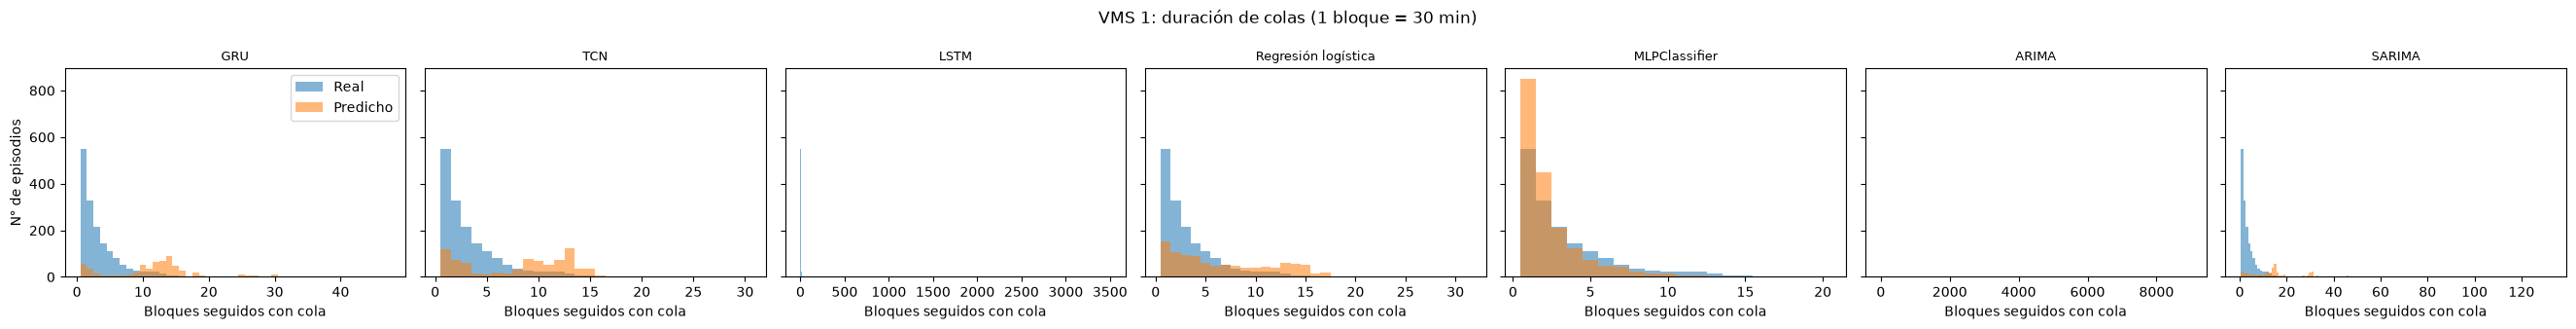

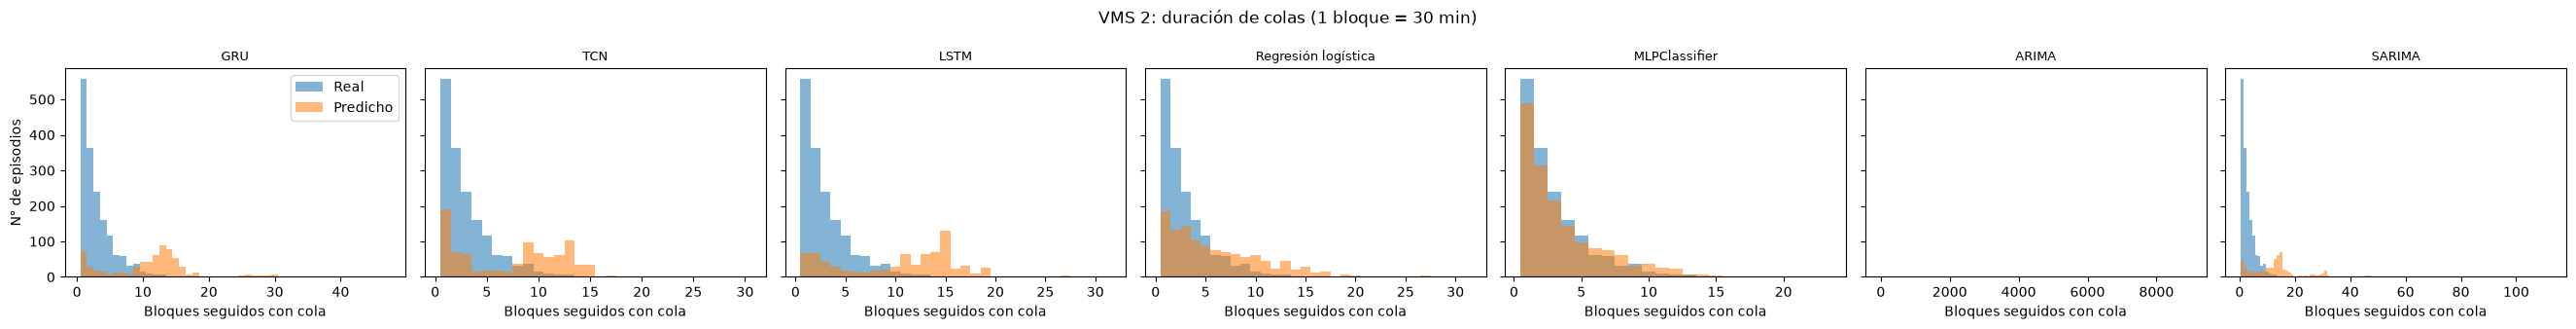

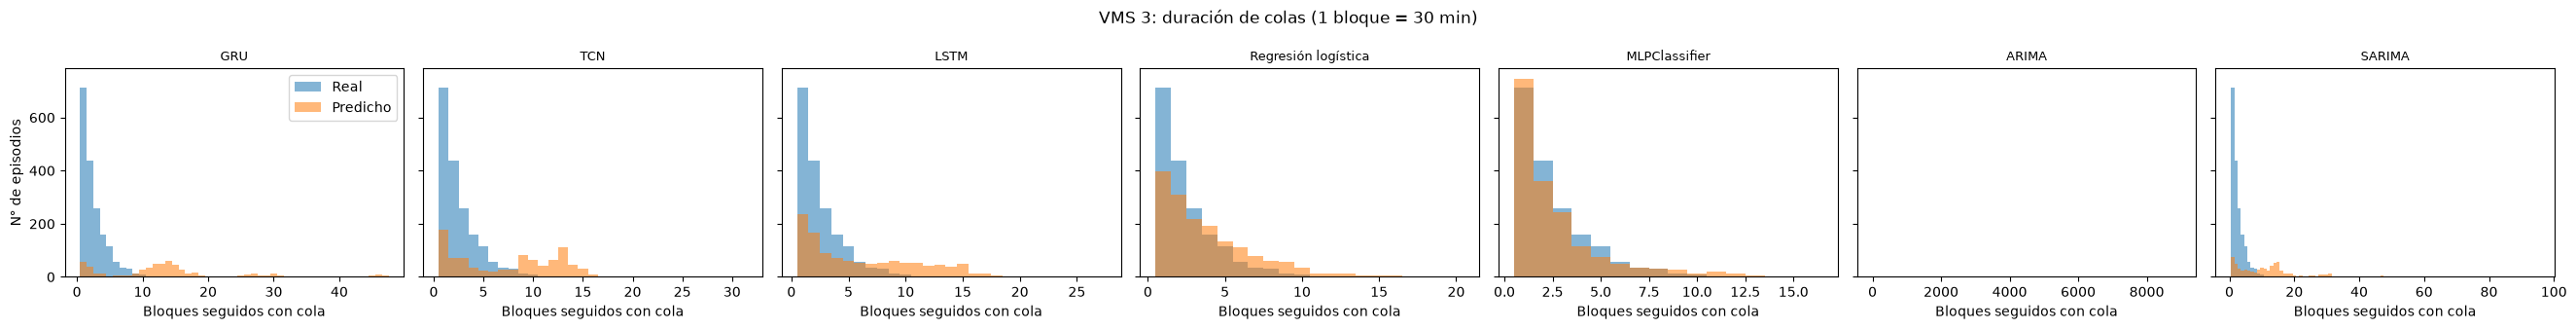

In [18]:
def find_episodes(values, times):
    """Posiciones (inicio, fin) de rachas de 1 en bloques contiguos de 30 min."""
    if len(values) == 0:
        return np.array([], int), np.array([], int)
    gap = np.r_[False, np.diff(times) != np.timedelta64(30, "m")]
    change = np.r_[True, values[1:] != values[:-1]] | gap
    starts = np.flatnonzero(change)
    ends = np.r_[starts[1:] - 1, len(values) - 1]
    keep = values[starts] == 1
    return starts[keep], ends[keep]


def machine_episode_report(g):
    """Compara episodios reales vs predichos de una máquina (g ya ordenado por tiempo)."""
    y_t, y_p = g["y_true"].to_numpy(), g["y_pred"].to_numpy()
    t = g["bloque_tiempo"].to_numpy(dtype="datetime64[ns]")
    rs, re_ = find_episodes(y_t, t)
    ps, pe = find_episodes(y_p, t)

    real_eps = []
    for s, e in zip(rs, re_):
        hits = np.flatnonzero(y_p[s:e + 1])
        row = {"inicio": t[s], "bloques_real": e - s + 1, "detectada": len(hits) > 0}
        if len(hits):
            first, last = s + hits[0], s + hits[-1]
            k_last = np.searchsorted(ps, last, side="right") - 1
            row.update({
                "retraso_inicio_bloques": hits[0],         # >0: el modelo avisa tarde
                "bloques_pred_dentro": len(hits),
                "fin_pred_menos_fin_real": pe[k_last] - e,  # >0: la predicción tarda en "bajar"
            })
        real_eps.append(row)

    cum = np.r_[0, np.cumsum(y_t)]
    false_alarm = [(cum[e + 1] - cum[s]) == 0 for s, e in zip(ps, pe)]
    pred_eps = pd.DataFrame({
        "inicio": t[ps] if len(ps) else [], "bloques_pred": pe - ps + 1,
        "falsa_alarma": false_alarm,
    })
    return (
        pd.DataFrame(real_eps), pred_eps,
        pd.DataFrame({"bloques": re_ - rs + 1}), pd.DataFrame({"bloques": pe - ps + 1}),
    )


summary_rows, episode_store = [], {}
for name in model_names:
    for machine in machines:
        g = frames[name].loc[frames[name]["ms"] == machine].sort_values("bloque_tiempo")
        real_df, pred_df, real_len, pred_len = machine_episode_report(g)
        episode_store[(machine, name)] = (real_df, pred_df, real_len, pred_len)

        det = real_df["detectada"] if len(real_df) else pd.Series(dtype=bool)
        summary_rows.append({
            "ms": machine, "modelo": name,
            "episodios_real": len(real_len), "episodios_pred": len(pred_len),
            "dur_media_real_h": real_len["bloques"].mean() * BLOCK_HOURS,
            "dur_media_pred_h": pred_len["bloques"].mean() * BLOCK_HOURS,
            "dur_mediana_real_h": real_len["bloques"].median() * BLOCK_HOURS,
            "dur_mediana_pred_h": pred_len["bloques"].median() * BLOCK_HOURS,
            "dur_max_real_h": real_len["bloques"].max() * BLOCK_HOURS,
            "dur_max_pred_h": pred_len["bloques"].max() * BLOCK_HOURS,
            "colas_detectadas_%": 100 * det.mean() if len(det) else np.nan,
            "retraso_inicio_med_h": (
                real_df.get("retraso_inicio_bloques", pd.Series(dtype=float)).median() * BLOCK_HOURS
            ),
            "desfase_fin_med_h": (
                real_df.get("fin_pred_menos_fin_real", pd.Series(dtype=float)).median() * BLOCK_HOURS
            ),
            "falsas_alarmas_%": 100 * pred_df["falsa_alarma"].mean() if len(pred_df) else np.nan,
        })

episode_summary = pd.DataFrame(summary_rows)
print(episode_summary.round(2).to_string(index=False))
episode_summary.to_csv(out_dir / "resumen_episodios.csv", index=False)

# Histogramas de duración de episodios: real vs predicho (una figura por máquina)
for machine in machines:
    fig, axes = plt.subplots(1, len(model_names), figsize=(3.8 * len(model_names), 3.4),
                             sharey=True, squeeze=False)
    for ax, name in zip(axes[0], model_names):
        _, _, real_len, pred_len = episode_store[(machine, name)]
        top = max(real_len["bloques"].max() if len(real_len) else 1,
                  pred_len["bloques"].max() if len(pred_len) else 1)
        bins = np.arange(1, top + 2) - 0.5
        ax.hist(real_len["bloques"], bins=bins, alpha=0.55, label="Real")
        ax.hist(pred_len["bloques"], bins=bins, alpha=0.55, label="Predicho")
        ax.set_title(name, fontsize=9)
        ax.set_xlabel("Bloques seguidos con cola")
    axes[0, 0].set_ylabel("N° de episodios")
    axes[0, 0].legend()
    fig.suptitle(f"{machine}: duración de colas (1 bloque = 30 min)")
    fig.tight_layout()
    plt.show()

## 4) Tendencias: cuándo ocurren (hora, día de semana, temporada)

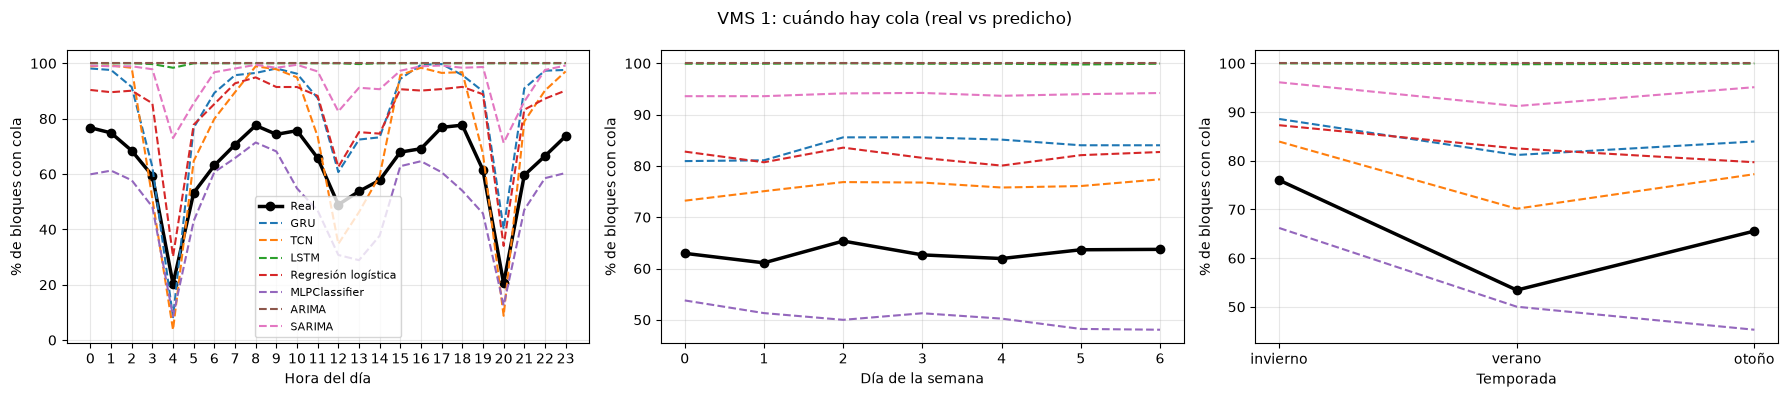

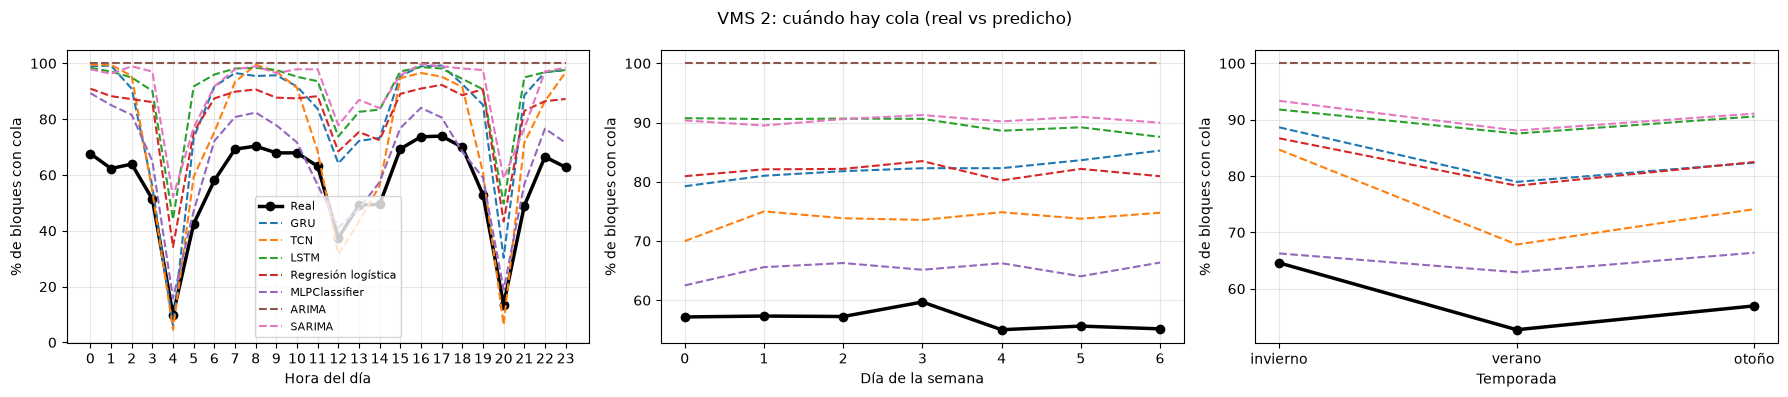

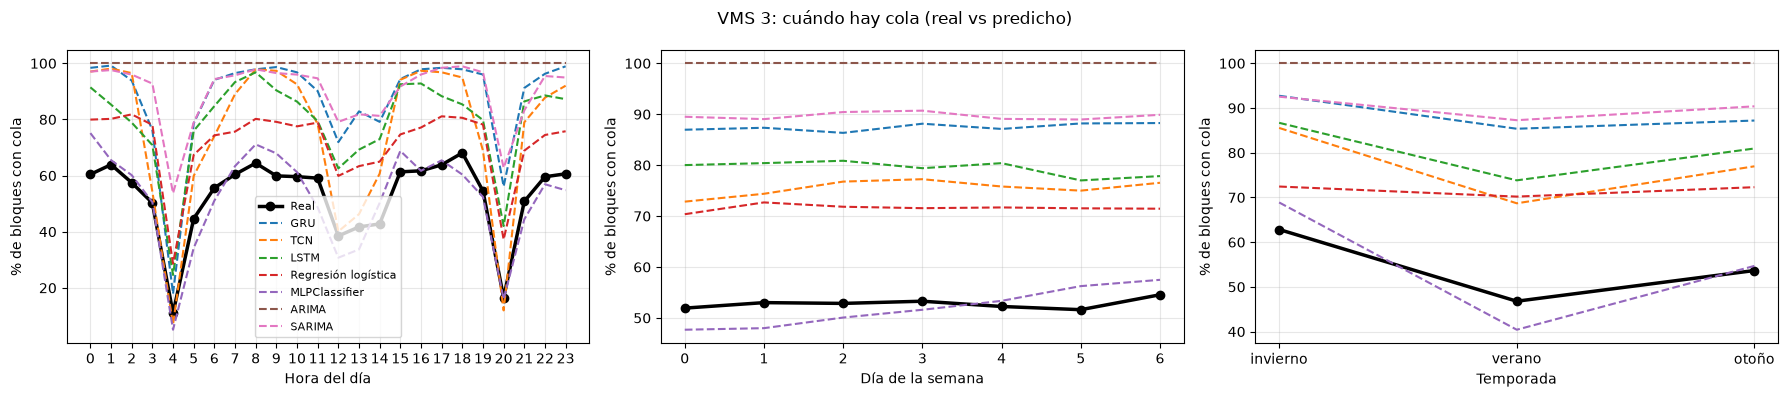

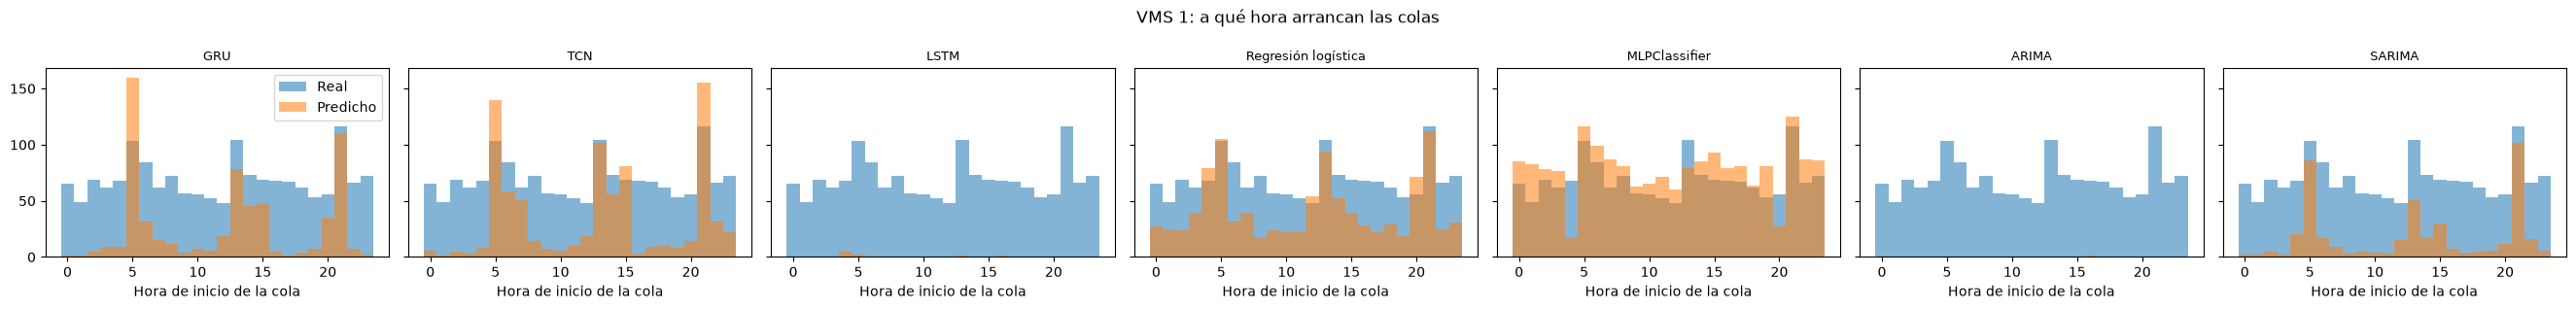

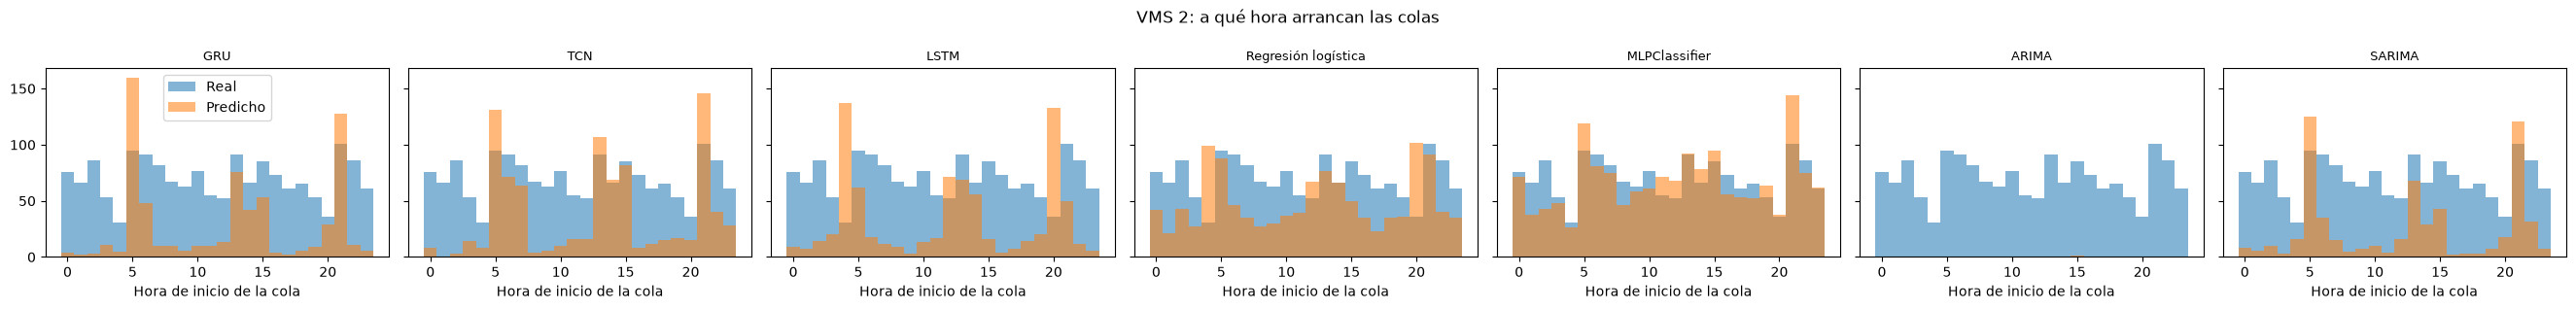

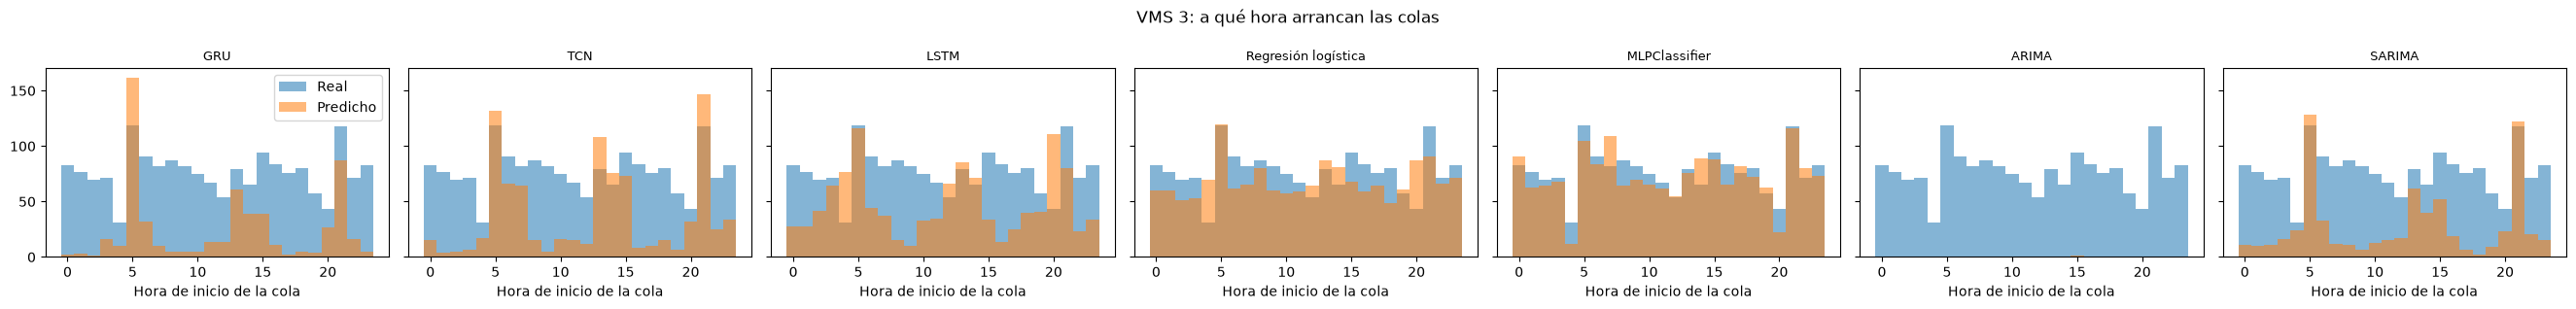

In [19]:
def profile(df, col, value):
    return df.groupby(col)[value].mean().mul(100)


for machine in machines:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for ax, (col, label) in zip(axes, [("hora", "Hora del día"),
                                       ("dia_semana", "Día de la semana"),
                                       ("temporada", "Temporada")]):
        real = profile(base.loc[base["ms"] == machine], col, "y_true")
        if col == "temporada":
            order = [s for s in ["invierno", "primavera", "verano", "otoño"] if s in real.index]
            real = real.reindex(order)
        ax.plot(real.index.astype(str), real.values, "k-o", lw=2.5, label="Real")
        for name in model_names:
            g = frames[name].loc[frames[name]["ms"] == machine]
            pr = profile(g, col, "y_pred").reindex(real.index)
            ax.plot(real.index.astype(str), pr.values, "--", label=name)
        ax.set_xlabel(label)
        ax.set_ylabel("% de bloques con cola")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(f"{machine}: cuándo hay cola (real vs predicho)")
    fig.tight_layout()
    plt.show()

# Hora de inicio de los episodios (real vs predicho)
for machine in machines:
    fig, axes = plt.subplots(1, len(model_names), figsize=(3.8 * len(model_names), 3.2),
                             sharey=True, squeeze=False)
    for ax, name in zip(axes[0], model_names):
        real_df, pred_df, _, _ = episode_store[(machine, name)]
        rh = pd.to_datetime(real_df["inicio"]).dt.hour if len(real_df) else pd.Series(dtype=int)
        ph = pd.to_datetime(pred_df["inicio"]).dt.hour if len(pred_df) else pd.Series(dtype=int)
        bins = np.arange(0, 25) - 0.5
        ax.hist(rh, bins=bins, alpha=0.55, label="Real")
        ax.hist(ph, bins=bins, alpha=0.55, label="Predicho")
        ax.set_title(name, fontsize=9)
        ax.set_xlabel("Hora de inicio de la cola")
    axes[0, 0].legend()
    fig.suptitle(f"{machine}: a qué hora arrancan las colas")
    fig.tight_layout()
    plt.show()